In [1]:
import time
import numpy as np
import scipy as sp
from scipy.integrate import solve_ivp
from scipy.special import j1
import matplotlib.pyplot as plt
from functools import partial
from pathlib import Path
import sys
current_dir = Path.cwd().resolve()
repo_root = next(
    (p for p in [current_dir, *current_dir.parents] if (p / "opius").is_dir()),
    None
)
if repo_root is None:
    raise FileNotFoundError("Could not find the 'opius' package directory in any parent folder.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from opius.config.system_configuration import *
from opius.physics.fuel_conduction_Model import Fuel
from opius.physics.coolantProperties import HB40
from opius.physics.physics_helper import HB40_h_correlations, CHF_HB40
from opius.physics.point_kinetics import rho_CR_func, point_kinetics_linear, p, point_kinetics_nonlinear
from opius.components.density_locks import solve_density_locks
from opius.components.channel_1D import Channel1D
from opius.components.hydraulics_helper import pump_head, derivatives_mq, S_a_func, S_b_func, S_c_func
from opius.components.build_system import build_channels
DATA_DIR = (repo_root / "opius" / "data").resolve()

# Time tracking
start = time.time()
time_calculating_transient_fuel_nodes = 0

# -- Parameters and safegaurds -- #
BURNUP_VALS = [0.0, 0.1, 0.5, 1, 2, 3, 4, 5, 6, 7, 8] # [MWd/kgHM]
DAYS_VALS = [0.0, 4.06776, 20.3388, 40.6776, 81.3551, 122.033, 162.71, 203.388, 244.065, 284.743, 325.421] # [day]

if pump_trip_transient and feedwater_loss_transient:
    raise ValueError('Cannot run 2 transients simultaneously')
evaluate_CHF = evaluate_hot and evaluate_CHF #CHF is evaluated only if hot channel is also evaluated

# -- Coolant and reactivity properties -- #
alpha_doppler_through_burnup = np.load(DATA_DIR / "OPIUSV4_Doppler_coeffs.npy")
alpha_doppler = alpha_doppler_through_burnup[BURNUP_INDEX] # [pcm/ C°] Fuel doppler temperature coefficient [c00, c01, c02, c03, c10, c11, c12, c20, c21, c30] and for example c01 * C_B while c21 * T_M**2 * C_B
MB_3rd_degree_polynomial_interpolation_coeffs_through_burnup = np.load(DATA_DIR / "OPIUSV4_poly_coeffs.npy") # [[4114.347312824663,-18.775443320966247,0.0024942237476326713,-4.826190718176804e-07,-8.25753045063111,0.00892126894680759,-6.044312645947514e-07,-0.007413410826815005,2.62490610858368e-06,-5.678949873744177e-06], [3994.308722724302,-18.656175441792602,0.002500483442742122,-5.209401727768181e-07,-8.985864403341212,0.0089523616686595,-2.5905677691895335e-07,-0.004776451882640096,6.529295358825848e-07,-6.998395806645519e-06], [4224.802598438185,-18.1343263728802,0.002198525706508702,-4.0075849483400816e-07,-9.516336589423418,0.009178029165243292,-6.567591324113664e-07,-0.0036993202794729416,1.9977112186708723e-06,-8.401191773810268e-06], [4339.113233837363,-17.826919776673215,0.0023903127819443967,-4.7490788190884814e-07,-8.779569102827955,0.00999733962720164,-6.533443581702159e-07,-0.009156021868942725,-4.6834530964545706e-07,1.4259600166210973e-06], [4341.928891455808,-16.531691754395425,0.0020319610006518055,-4.239557434004837e-07,-9.460318189712437,0.007522795458787565,-2.13346593280761e-07,-0.004623619408734656,2.3667307248453895e-06,-6.989784435529334e-06], [4401.019009762118,-15.967735883316639,0.0018609386274608501,-3.503916659042261e-07,-11.277660840057727,0.007291387314473081,-3.578008023197299e-07,0.0031871109304660696,2.681154608774605e-06,-1.8406542845350593e-05], [4086.342396692569,-15.384961279494089,0.0014856721957918068,-2.503680960330712e-07,-6.70267244777903,0.007758418630633609,-1.3620328376262592e-07,-0.019076609672600407,6.89080534965747e-07,1.1250805945411946e-05], [4506.76265822229,-15.243870464619198,0.0017182812417707756,-3.3897870110877193e-07,-11.392998364787127,0.00834702038177682,-2.3631918821820364e-07,-0.003179820276060142,-1.0685914225150306e-06,-6.590524746080684e-06], [4449.201818641892,-14.649453320954951,0.0014350357017174492,-2.82035955478932e-07,-9.467208860423284,0.006278987200739494,1.0101711733767615e-07,-0.0103034528703396,2.110753990980374e-06,-1.1678556847138921e-06], [4612.952959345028,-14.700294383251547,0.001494402682482807,-2.863843899802987e-07,-11.347941006332475,0.008701510822252186,-3.1068044092918967e-07,-0.0066980354370056935,-1.990364345172413e-06,-2.7498768470912704e-06], [4389.229300713625,-14.50438977558863,0.0016994474798821928,-3.534942560889931e-07,-11.229469463493189,0.0057266468121750565,-2.481350400707072e-07,-0.0032128126714752224,3.840347834960234e-06,-1.4319818679553453e-05]]
MB_3rd_degree_polynomial_interpolation_coeffs = MB_3rd_degree_polynomial_interpolation_coeffs_through_burnup[BURNUP_INDEX]

if not burnup_dependent_delayed_neutrons:
    Lambda = 2.5e-5 #s
    lambda_i = np.array([0.0124, 0.0305, 0.111, 0.301, 1.14, 3.01]) #1/s
    beta_i = np.array([0.000215, 0.001424, 0.001274, 0.002568, 0.000748, 0.000273])
else:
    Lambda = np.load(DATA_DIR / "OPIUSV4_gen_times.npy")[BURNUP_INDEX]
    lambda_i = np.load(DATA_DIR / "OPIUSV4_lambda_is.npy")[BURNUP_INDEX]
    beta_i = np.load(DATA_DIR / "OPIUSV4_beta_is.npy")[BURNUP_INDEX]

beta = np.sum(beta_i)
HB_conc = HB40(HB = HB_wt) # High boilers concentration [wt%]
irradiated = HB_conc.HB > 5 # 5% wt is an arbitrary threshold for irradiated HB40

# -- Geometry and Channel Construction -- #
R_core = Dh_b /2
channel_a, channel_b, channel_c, idx_core, lock_areas, n_interface = build_channels(HB_conc)
n_interface_Ldl, n_interface_Udl = n_interface
idx_start_core, idx_exit_core = idx_core
A_LDl, A_UDl = lock_areas

x_a, x_b, x_c = channel_a.x, channel_b.x, channel_c.x
dx_a, dx_b, dx_c = channel_a.dx, channel_b.dx, channel_c.dx
x_core = x_b[idx_start_core:idx_exit_core]
A_a_array, A_b_array, A_c_array = channel_a.A, channel_b.A, channel_c.A

# peaking factors (careful that they are capped by nature) and extrapolation dimensions calculation
f_R_channel = np.load(DATA_DIR / "OPIUSV4_max_radial_pfs.npy")[BURNUP_INDEX]
f_A = np.load(DATA_DIR / "OPIUSV4_avg_axial_pfs.npy")[BURNUP_INDEX]
f_A_hot = np.load(DATA_DIR / "OPIUSV4_pow_axial_pfs.npy")[BURNUP_INDEX]
f_R = f_R_channel * f_channel

def f_A_minimize(H_core_tilde, f_A):
    return np.pi * H_core / (2 * H_core_tilde * np.sin(np.pi / 2 * H_core / H_core_tilde)) - f_A

def f_R_minimize(R_core_tilde, f_R):
    return 2.405 * R_core / (2 * R_core_tilde * j1(2.405 * R_core / R_core_tilde)) - f_R
H_core_tilde = sp.optimize.fsolve(f_A_minimize, 1.2 * H_core, f_A)[0] # 1.2 * H_core for the initial guess
H_core_tilde_hot = sp.optimize.fsolve(f_A_minimize, 1.2 * H_core, f_A_hot)[0] 
R_core_tilde = sp.optimize.fsolve(f_R_minimize, 1.2 * R_core, f_R)[0] # 1.2 * R_core for the initial guess

# Fuel and lattice
number_pins = n_fuel_assembly * n_rods_assembly  # [-] 
r_co = d_r / 2 # [m] 
r_go = r_co - clad_thickness # [m] 
r_fo = r_go - gas_gap_thickness # [m] 
D_h = d_r * (4 / np.pi * (pitch / d_r)**2 - 1) # hydraulic diameter
Dh_c = np.sqrt(4 * A_c_array / np.pi) #m
P_H = number_pins * 2 * np.pi * r_co
V_fuel = number_pins * np.pi * r_fo**2 * H_core

average_fuel_volumetric_heating_SS_W = Q_core_SS / V_fuel * 1000
peak_fuel_volumetric_heating_SS_W = average_fuel_volumetric_heating_SS_W * f_A * f_R
peak_fuel_volumetric_heating_SS_W_hot = average_fuel_volumetric_heating_SS_W * f_A_hot * f_R

# --Source term functions-- #
S_b_correction_factor = 1.0 # ensure target core power generation is met
S_c_correction_factor = 1.0  # ensure target HX power removal is met
S_c_func = partial(S_c_func, x_c = x_c)
S_b_func = partial(S_b_func, P_H = P_H)

# core object with fuel nodes. Averaged for system modeling. Will be re-created later with corrected volumetric heating
max_steps = 10000
core = np.array([
    Fuel(1, peak_fuel_volumetric_heating_SS_W / f_R * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde), None, None)
    if i >= idx_start_core and i < idx_exit_core
    else None
    for i in range(len(x_b))
], dtype=object) # np.where was putting the same Fuel object everywhere

Total_P_b_SS = np.sum(S_b_func(core, 0)[:-1]) * dx_b * A_core # W
Total_P_c_SS = np.sum(S_c_func(0.0, S_c_correction_factor = S_c_correction_factor)[:-1]) * dx_c * A_c_SG # W
S_b_correction_factor = Q_core_SS / Total_P_b_SS
S_c_correction_factor = - Q_core_SS / Total_P_c_SS

# post-correction, recreate the nodes from volumetric heating with the correction factor for proper initialization sequence
core = np.array([
    Fuel(max_steps, peak_fuel_volumetric_heating_SS_W * S_b_correction_factor / f_R * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde), None, None)
    if i >= idx_start_core and i < idx_exit_core
    else None
    for i in range(len(x_b))
], dtype=object) # np.where was putting the same Fuel object everywhere

if evaluate_hot:
    core_hot = np.array([
        Fuel(max_steps, peak_fuel_volumetric_heating_SS_W_hot * S_b_correction_factor * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde_hot), None, None)
        if i >= idx_start_core and i < idx_exit_core
        else None
        for i in range(len(x_b))
    ], dtype=object)
                
S_b = S_b_func(core, 0)
S_c = S_c_func(0, S_c_correction_factor = S_c_correction_factor)
if evaluate_hot : 
    S_b_hot = S_b_func(core_hot, 0)

# --Find steady state conditions at the initial parameters--#
i_a_initial = np.full(nx_a, HB_conc.h_T(T_pool)) # Profile A
i_b_initial = np.empty(nx_b)
i_b_initial[0] = HB_conc.h_T(T_l)
i_a_initial[-n_interface_Ldl:] = i_b_initial[0]

for i in range(1, nx_b):
    i_b_initial[i] = i_b_initial[i-1] + S_b[i] * dx_b * A_b_array[i] / (nominal_mass_flow)
i_a_initial [0 : n_interface_Udl] = i_b_initial[-1]

i_c_initial = np.empty(nx_c)
i_c_initial[0] = i_b_initial[-1]  # inlet BC: hot exit of B feeds i=0 of C
for i in range(1, nx_c):
    i_c_initial[i] = i_c_initial[i-1] + S_c[i] * dx_c * A_c_array[i] / (nominal_mass_flow)

Cb_a_initial = np.full(nx_a, float(Boron_concentration_pool))
Cb_a_initial[-n_interface_Udl:] = 0.0
Cb_a_initial[ :n_interface_Ldl] = 0.0
Cb_b_initial = np.zeros(nx_b)
Cb_c_initial = np.zeros(nx_c)

channel_a.set_initial_profile(i_a_initial, Cb_a_initial)
channel_b.set_initial_profile(i_b_initial, Cb_b_initial)
channel_c.set_initial_profile(i_c_initial, Cb_c_initial)

rho_a_initial = channel_a.rho
rho_b_initial = channel_b.rho
rho_c_initial = channel_c.rho

J_a_initial = channel_a.get_Jq()
J_b_initial = channel_b.get_Jq()
J_c_initial = channel_c.get_Jq()

# -- Pressure losses -- #
P_fl_b_initial = channel_b.get_friction_loss(nominal_mass_flow)
P_acc_b_initial = channel_b.get_acc_loss()
F_b_initial_th =  g * (J_a_initial + J_b_initial) / (nominal_mass_flow**2) # sum of total pressure losses coefficient in in channel B to maintain equilibrium
rho_core_initial = np.average(rho_b_initial[idx_start_core : idx_exit_core])
P_spacer = F_b_initial_th - (P_fl_b_initial + P_acc_b_initial)
zeta_spacer = 2 * rho_core_initial * P_spacer #pressure loss coefficient for spacer grids in the core
F_b = P_fl_b_initial + P_acc_b_initial + P_spacer

P_fl_c = channel_c.get_friction_loss(nominal_mass_flow)
P_acc_c = channel_c.get_acc_loss()
zeta_steam_generator = zeta_spacer * 2
Pl_SG = zeta_steam_generator / (np.average(rho_c_initial) * 2 ) #arbitrary value for the losses in the steam generator
F_c = P_fl_c + P_acc_c + Pl_SG

zeta_exp = (1 - A_UDl / A_a_in)**2
A_center = A_b * (0.62 + 0.38 * (A_LDl / A_a_in)**3)
zeta_cont =  (A_LDl / A_center - 1)**2
P_Udl = zeta_exp / (2 * rho_a_initial[n_interface_Udl + 1] * A_UDl**2)
P_Ldl = zeta_cont / (2 * rho_b_initial[-n_interface_Ldl - 1] * A_LDl**2)
F_a = (P_Udl + P_Ldl) 

if evaluate_hot:
    i_b_initial_hot = np.empty(nx_b)
    i_b_initial_hot[0] = i_b_initial[0]
    for i in range(1, nx_b):
        i_b_initial_hot[i] = i_b_initial_hot[i-1] + S_b_hot[i] * dx_b * A_b_array[i] / (nominal_mass_flow) 
    T_b_initial_hot = HB_conc.T_h(i_b_initial_hot)
    roughness_b = np.full(nx_b, roughness_else)
    roughness_b[idx_start_core:idx_exit_core] = roughness_core
    Dh_b_array = np.full(nx_b, Dh_b)
    Dh_b_array[idx_start_core:idx_exit_core] = D_h
    hot_channel = Channel1D("Hot Channel", L_b, nx_b, A_b_array, channel_b.theta, roughness_b, HB_conc, Dh_b_array)
    hot_channel.set_initial_profile(i_b_initial_hot, Cb_b_initial)

# Solve the S.S. fuel thermal conduction to serve as transient I.C.
last = 0
for i in range(len(core)):
    if core[i] is not None:
        # core average pin
        core[i].T_lb[0] = channel_b.T[i]
        core[i].h[0] = HB40_h_correlations(core[i].T_lb[0], nominal_mass_flow, HB_conc, A_core, D_h, irradiated = irradiated)
        core[i].solve(-1) # solve core S.S.
        core[i].z = x_b[i]
        last = i
        # core hot pin
        if evaluate_hot :
            core_hot[i].T_lb[0] = T_b_initial_hot[i]
            core_hot[i].h[0] = HB40_h_correlations(core_hot[i].T_lb[0], nominal_mass_flow, HB_conc, A_core, D_h, irradiated = irradiated)
            core_hot[i].solve(-1) # solve hot core S.S.
            core_hot[i].z = x_b[i]

if evaluate_CHF:
    heat_flux_hot_kWm2 = np.array([core_hot[idx_start_core + k].hf_co[0] / 1000.0 for k in range(idx_exit_core - idx_start_core)])
    CHF_initial = CHF_HB40(T_b_initial_hot[idx_start_core:idx_exit_core], P_initial, nominal_mass_flow, HB_conc, A_core, irradiated=irradiated)
    MDNBR_initial = np.min(CHF_initial / heat_flux_hot_kWm2)
    if MDNBR_initial < 1.0:
        print(f"CHF exceeded: MDNBR = {MDNBR_initial}")

#point kinetics setup
n0 = 10
C0 = (beta_i * n0) / (lambda_i * Lambda) 
y0_point_kinetics = np.concatenate(([n0], C0))
enthalpy_core = i_b_initial[idx_start_core : idx_exit_core]
enthalpy_avg_core = np.sum(enthalpy_core[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])
T_avg_core_initial = HB_conc.T_h(enthalpy_avg_core)
MB_normalization_constant = -p(T_avg_core_initial, SS_boron_concentration, MB_3rd_degree_polynomial_interpolation_coeffs)
core_nodes = core[idx_start_core : idx_exit_core]
T_fuel = np.array([core_node.average_fuel_T[0] for core_node in core_nodes])
T_avg_fuel_initial = np.sum(T_fuel[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])

ma_0 = 0
mb_0 = nominal_mass_flow
mc_0 = mb_0  
delta_Pb_0 = F_b * np.abs(mb_0) * mb_0
delta_Pc_0 = F_c * np.abs(mc_0) * mc_0 
idx_exit_SG = np.abs(x_c - (x_start_SG + H_SG)).argmin()
n_pump = int(idx_exit_SG + 1) #the pump is at exit of SG
h_pump_SS = 1 / (channel_c.rho[n_pump] * g) * ((delta_Pc_0 + delta_Pb_0) - g * (J_b_initial + J_c_initial))

# initialize results
t = [0.0]
delta_time_target = delta_time
delta_time_temp = np.full(4, delta_time)  # CFL array

history = {
    "t": [0.0], "ma": [ma_0], "mb": [mb_0], "mc": [mc_0],
    "i_a": [channel_a.i.copy()], "i_b": [channel_b.i.copy()], "i_c": [channel_c.i.copy()],
    "Cb_a": [channel_a.Cb.copy()], "Cb_b": [channel_b.Cb.copy()], "Cb_c": [channel_c.Cb.copy()],
    "Ja": [J_a_initial], "Jb": [J_b_initial], "Jc": [J_c_initial],
    "T_b": [channel_b.T.copy()], "P_b": [Q_core_SS], "P_c": [-Q_core_SS],
    "Q_core": [Q_core_SS], "Cb_avg": [0.0],
    "T_avg_core": [T_avg_core_initial], "T_avg_fuel": [T_avg_fuel_initial],
}
if evaluate_CHF:
    history["MDNBR"] = [MDNBR_initial]
if evaluate_hot:
    history["i_b_hot"] = [i_b_initial_hot.copy()]
    history["T_b_hot"] = [T_b_initial_hot.copy()]
#------------------------------------
# Transient
#------------------------------------
j = 1
Power_change = 1
Cb_avg = 0.0

i_a = channel_a.i.copy()
i_b = channel_b.i.copy()
i_c = channel_c.i.copy()
Cb_a = channel_a.Cb.copy()
Cb_b = channel_b.Cb.copy()
Cb_c = channel_c.Cb.copy()
i_b_hot = i_b_initial_hot.copy() if evaluate_hot else None
T_b_hot = T_b_initial_hot.copy() if evaluate_hot else None

while t[j-1] < Time:
    # 1) Check the CFL limit and adjust delta t accordingly
    CFL_a = np.abs(ma_0) / (channel_a.rho * A_a_array) * delta_time / dx_a 
    CFL_b = np.abs(mb_0) / (channel_b.rho * A_b_array) * delta_time / dx_b 
    CFL_c = np.abs(mc_0) / (channel_c.rho * A_c_array) * delta_time / dx_c
    if np.any(CFL_a > 1) :
        delta_time_temp [1] = dx_a * A_LDl * np.min(channel_a.rho) / np.abs(ma_0) * 0.8
    if np.any(CFL_b > 1) :
        delta_time_temp [2] = dx_b * A_core * np.min(channel_b.rho) / np.abs(mb_0) * 0.8
    if np.any(CFL_c > 1) :
        delta_time_temp [3] = dx_c * A_c_cl * np.min(channel_c.rho) / np.abs(mc_0) * 0.8
    delta_time = np.min(delta_time_temp)
    t.append(t[j-1] + delta_time )# current time

    # 2) solve the differential equations to get the flows at time t0+delta time
    t_eval = np.linspace(t[j-1], t[j], 2)
    t_span = (t[j-1], t[j])
    y0 = [ma_0, mb_0]
    hp_current = pump_head(t[j], h_pump_SS, pump_trip_transient=pump_trip_transient, feedwater_loss_transient=feedwater_loss_transient)
    sol = solve_ivp(derivatives_mq, t_span, y0, t_eval=t_eval, method='BDF', args = (hp_current, channel_a, channel_b, channel_c, F_a, F_b, F_c, channel_c.rho[n_pump]))
    ma_0 = sol.y[0][-1]
    mb_0 = sol.y[1][-1]
    mc_0 = mb_0 - ma_0

    # 3) initialize  B.C. for advection based on flow regime
    i_a, i_b, i_c, i_b_hot, Cb_a, Cb_b, Cb_c = solve_density_locks(ma_0, mb_0, mc_0, Cb_a, Cb_b, Cb_c, i_a, i_b, i_c, i_b_hot, evaluate_hot) #B.C through density locks

    # 4) Enthalpy and boron advection
    S_a = S_a_func(t[j])
    S_b = S_b_func(core, j-1)
    S_c = S_c_func(t[j], S_c_correction_factor = S_c_correction_factor)

    i_a, Cb_a = channel_a.upwind_scheme(ma_0, delta_time, S_a, np.zeros(nx_a))
    i_b, Cb_b = channel_b.upwind_scheme(mb_0, delta_time, S_b, np.zeros(nx_b))
    i_c, Cb_c = channel_c.upwind_scheme(mc_0, delta_time, S_c, np.zeros(nx_c))
    T_b = HB_conc.T_h(i_b)

    if evaluate_hot:
        S_b_hot = S_b_func(core_hot, j-1)
        i_b_hot, _ = hot_channel.upwind_scheme(mb_0, delta_time, S_b_hot, np.zeros(nx_b))
        T_b_hot = HB_conc.T_h(i_b_hot)

    # 5) Fuel conduction
    t1 = time.time()
    Q_core = Q_core_SS * Power_change
    peak_fuel_volumetric_heating_W = Q_core / V_fuel * 1000 * f_A * f_R
    
    for i in range(len(core)):
        if core[i] is not None:
            core[i].T_lb[j] = T_b[i] # uses previous coolant temperature as the liquid bulk temperature
            core[i].h[j] = HB40_h_correlations(core[i].T_lb[j], mb_0, HB_conc, A_core, D_h, irradiated = irradiated)
            core[i].volumetric_heating[j] = peak_fuel_volumetric_heating_W / f_R * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde) * S_b_correction_factor
            core[i].t[j] = t[j]
            # solve heat conduction to get values at time step j
            core[i].solve(j-1)
            last=i
            # core hot pin
            if evaluate_hot :
                core_hot[i].T_lb[j] = T_b_hot[i]
                core_hot[i].h[j] = HB40_h_correlations(core_hot[i].T_lb[j], mb_0, HB_conc, A_core, D_h, irradiated = irradiated)
                core_hot[i].volumetric_heating[j] = peak_fuel_volumetric_heating_W * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde_hot) * S_b_correction_factor
                core_hot[i].t[j] = t[j]
                core_hot[i].solve(j-1)
    time_calculating_transient_fuel_nodes += (time.time() - t1)

    # 6) Pressure losses
    #channel b
    P_spacer = zeta_spacer / (2 * np.average(channel_b.rho[idx_start_core : idx_exit_core]))
    F_b =  channel_b.get_friction_loss(mb_0) + channel_b.get_acc_loss() + P_spacer
    #channel c
    Pl_SG = zeta_steam_generator / (np.average(channel_c.rho) * 2 )
    F_c = channel_c.get_friction_loss(mc_0) + channel_c.get_acc_loss() + Pl_SG
    #channel a
    P_Udl = zeta_exp / (2 * channel_a.rho[n_interface_Udl + 1] * A_UDl**2)
    P_Ldl = zeta_cont / (2 * channel_b.rho[-n_interface_Ldl - 1] * A_LDl**2)
    F_a = channel_a.get_friction_loss(ma_0) + channel_a.get_acc_loss() + (P_Udl + P_Ldl)

    # 7) Point kinetics
    Cb_core = Cb_b[idx_start_core:idx_exit_core]
    Cb_avg = np.sum(Cb_core[:-1]) * (x_core[1] - x_core[0]) / (x_core[-1] - x_core[0])
    Delta_Cb = Cb_avg - 0.0

    enthalpy_avg_core = (np.sum(i_b[idx_start_core : idx_exit_core][:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0]))
    T_avg_core = HB_conc.T_h(enthalpy_avg_core)
    Delta_temp_core = T_avg_core - T_avg_core_initial

    T_fuel = np.array([core_node.average_fuel_T[j-1] for core_node in core_nodes])
    T_avg_fuel = ( np.sum(T_fuel[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0]))
    Delta_temp_fuel = T_avg_fuel - T_avg_fuel_initial

    if nonlinear_PK:
        sol_point_kinetics = solve_ivp(point_kinetics_nonlinear, t_span, y0_point_kinetics, t_eval = t_eval, args=(Cb_avg + SS_boron_concentration, T_avg_core, MB_3rd_degree_polynomial_interpolation_coeffs, MB_normalization_constant, Delta_temp_fuel,alpha_doppler, beta, Lambda, beta_i, lambda_i), method='Radau')
    else:
        sol_point_kinetics = solve_ivp(point_kinetics_linear, t_span, y0_point_kinetics, t_eval = t_eval, args=(Delta_Cb, alpha_B, Delta_temp_core, alpha_M, Delta_temp_fuel,alpha_doppler, beta, Lambda, beta_i, lambda_i), method='Radau')
    n_final = sol_point_kinetics.y[0, -1] # neutrons population change
    Power_change = max(n_final / n0, 1.9e-2) #model decay heat
    C0 = sol_point_kinetics.y[1:, -1] # final concentration decay groups
    y0_point_kinetics = np.concatenate(([n_final], C0)) # update new initial conditions with previous solutions

    # 8) Thermal marghins
    if evaluate_CHF:
        heat_flux_hot_t = np.array([core_hot[idx_start_core + k].hf_co[j] / 1000.0 for k in range(idx_exit_core - idx_start_core)])
        CHF_t = CHF_HB40(T_b_hot[idx_start_core:idx_exit_core], P_initial, mb_0, HB_conc, A_core, irradiated=irradiated)
        MDNBR_t = np.min(CHF_t / heat_flux_hot_t)
        if MDNBR_t < 1.0:
            print(f"CHF exceeded at t={t[j]:.2f} s: MDNBR = {MDNBR_t:.3f}")

    # 9) reset delta_time to the target value and save results
    delta_time = delta_time_target
    history["t"].append(t[j])
    history["ma"].append(ma_0)
    history["mb"].append(mb_0)
    history["mc"].append(mc_0)
    history["i_a"].append(i_a.copy())
    history["i_b"].append(i_b.copy())
    history["i_c"].append(i_c.copy())
    history["Cb_a"].append(Cb_a.copy())
    history["Cb_b"].append(Cb_b.copy())
    history["Cb_c"].append(Cb_c.copy())
    history["Ja"].append(channel_a.get_Jq())
    history["Jb"].append(channel_b.get_Jq())
    history["Jc"].append(channel_c.get_Jq())
    history["Cb_avg"].append(Cb_avg)
    history["T_b"].append(T_b.copy())
    history["P_b"].append(np.sum(S_b_func(core, j)[:-1]) * dx_b * A_core)
    history["P_c"].append(np.sum(S_c[:-1]) * dx_c * A_c_SG)
    history["Q_core"].append(Q_core)
    history["T_avg_core"].append(T_avg_core)
    history["T_avg_fuel"].append(T_avg_fuel)
    if evaluate_CHF:
        history["MDNBR"].append(MDNBR_t)
    if evaluate_hot:
        history["i_b_hot"].append(i_b_hot.copy())
        history["T_b_hot"].append(T_b_hot.copy())

    print(f"Simulation progress: {t[j] / Time * 100:.1f} % | Core Flow: {mb_0:.1f} kg/s | Power: {Power_change * 100:.1f} %")
    j += 1

print(f"j = {j}")
for key, values in history.items():
    if len(values) > 0:
        history[key] = np.asarray(values)
t = history['t']
for i in range(len(core)):
    if core[i] is not None:
        core[i].crop(j)
        if evaluate_hot : core_hot[i].crop(j)    
total_time = time.time() - start
fraction_nodes = time_calculating_transient_fuel_nodes / total_time
print(f"Calculating time : {total_time} , Simulated time : {t[-1]}")
print(f"Time calculating transient fuel nodes : {time_calculating_transient_fuel_nodes}")
print(f"Fraction spent on fuel nodes : {fraction_nodes}")

Simulation progress: 0.3 % | Core Flow: 14999.7 kg/s | Power: 100.0 %
Simulation progress: 0.7 % | Core Flow: 14999.1 kg/s | Power: 100.0 %
Simulation progress: 1.0 % | Core Flow: 14998.4 kg/s | Power: 100.0 %
Simulation progress: 1.4 % | Core Flow: 14997.5 kg/s | Power: 100.0 %
Simulation progress: 1.7 % | Core Flow: 14996.5 kg/s | Power: 100.0 %
Simulation progress: 2.1 % | Core Flow: 14995.3 kg/s | Power: 100.0 %
Simulation progress: 2.4 % | Core Flow: 14994.2 kg/s | Power: 100.0 %
Simulation progress: 2.8 % | Core Flow: 14992.9 kg/s | Power: 100.0 %
Simulation progress: 3.1 % | Core Flow: 14991.7 kg/s | Power: 100.0 %
Simulation progress: 3.5 % | Core Flow: 14990.4 kg/s | Power: 100.0 %
Simulation progress: 3.8 % | Core Flow: 14989.1 kg/s | Power: 100.0 %
Simulation progress: 4.2 % | Core Flow: 14987.8 kg/s | Power: 100.0 %
Simulation progress: 4.6 % | Core Flow: 14986.4 kg/s | Power: 100.0 %
Simulation progress: 4.9 % | Core Flow: 14985.1 kg/s | Power: 100.0 %
Simulation progress:

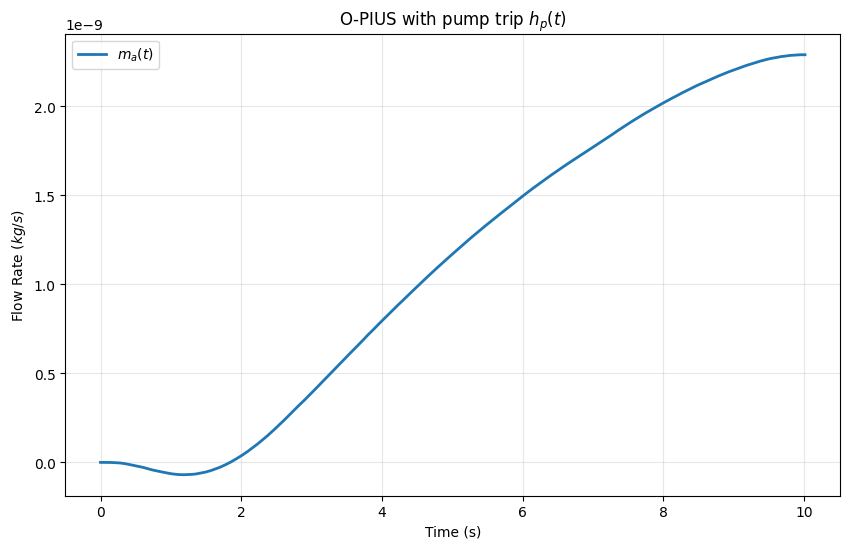

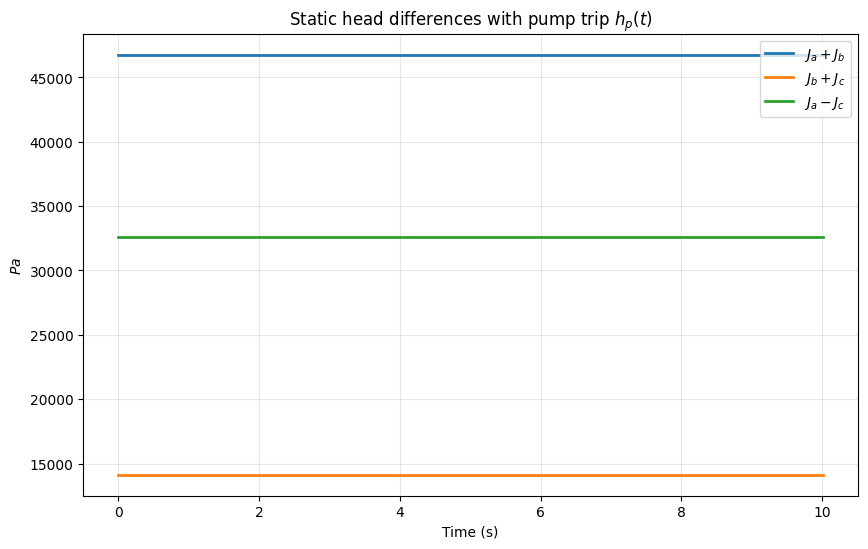

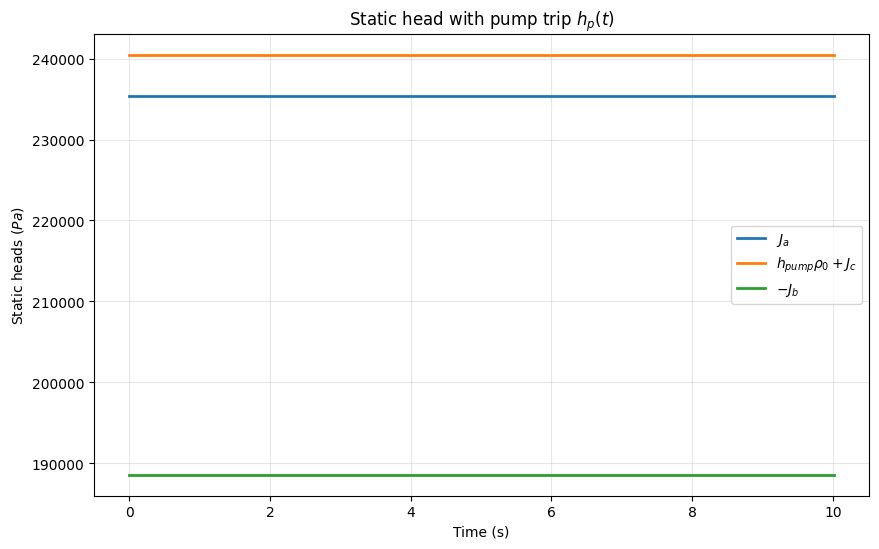

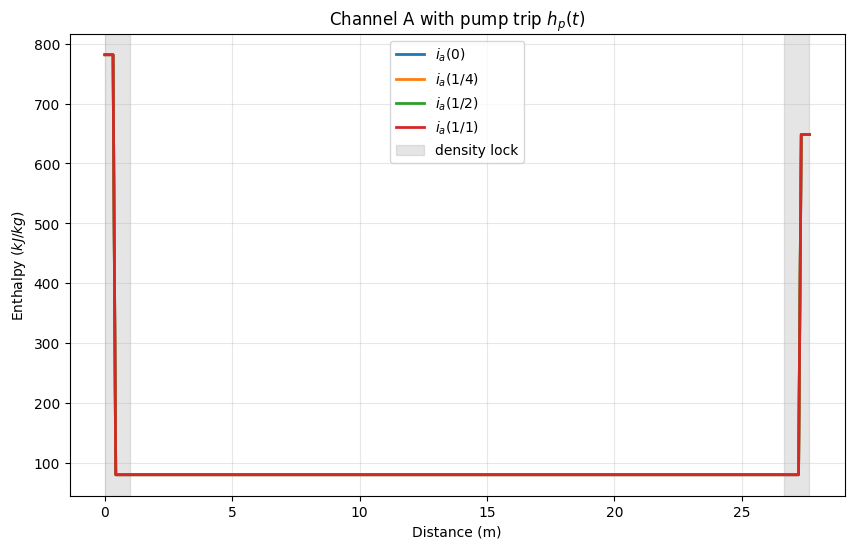

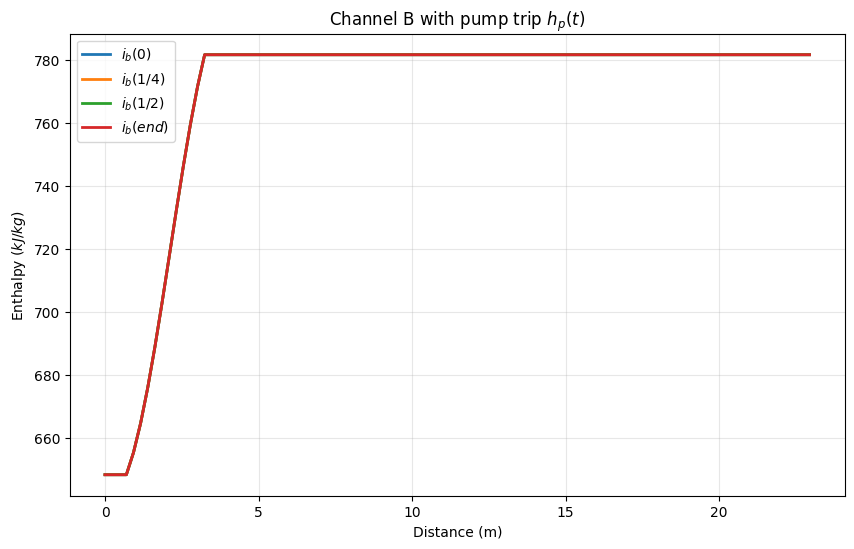

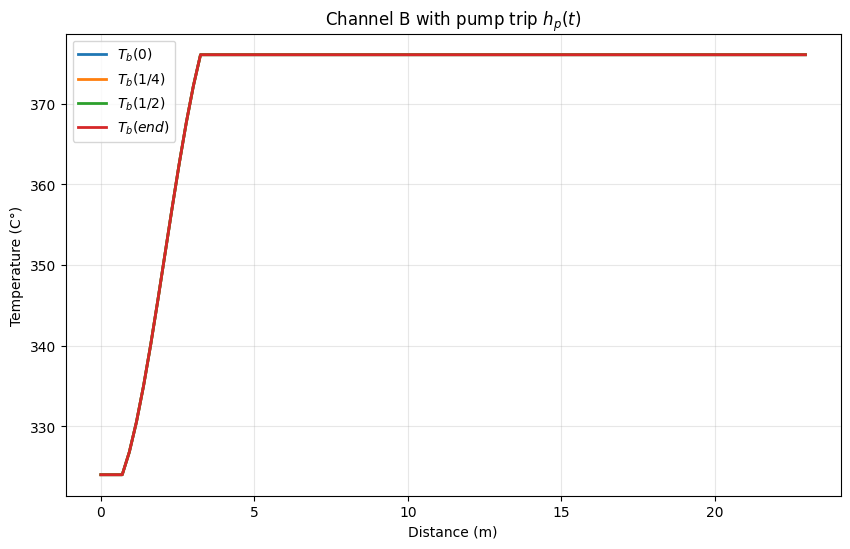

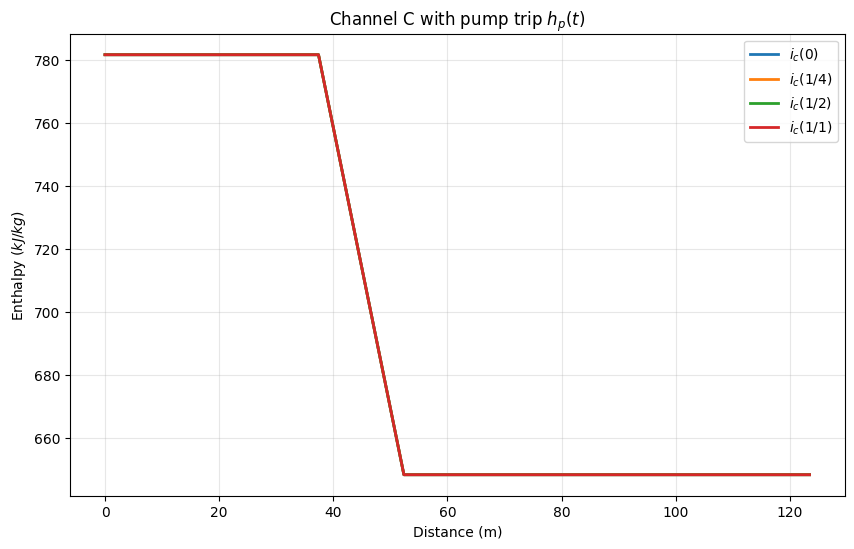

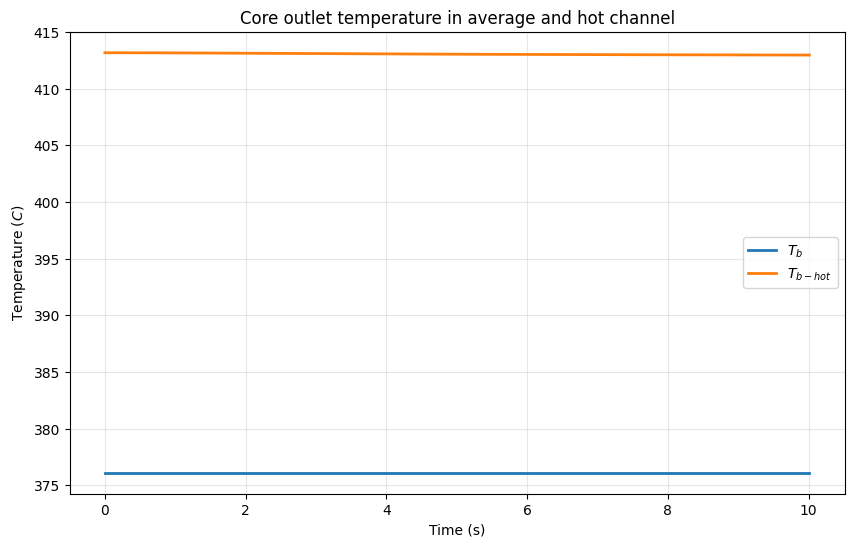

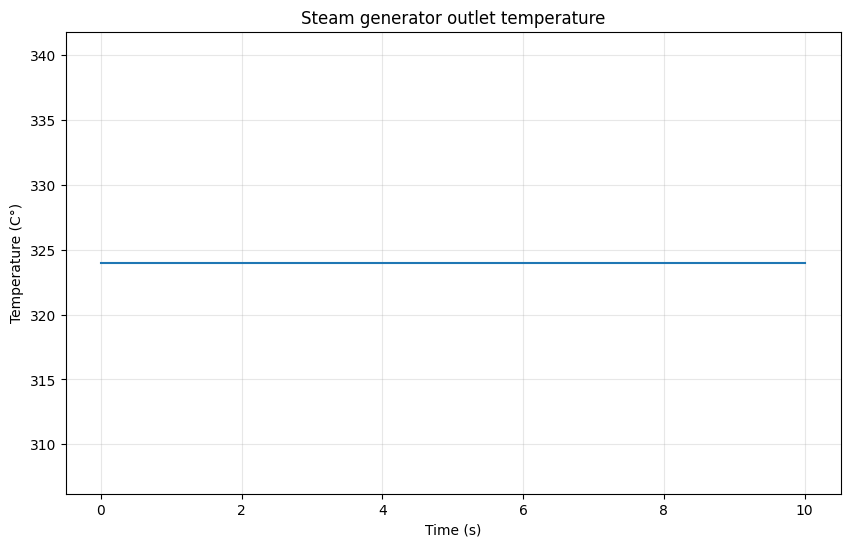

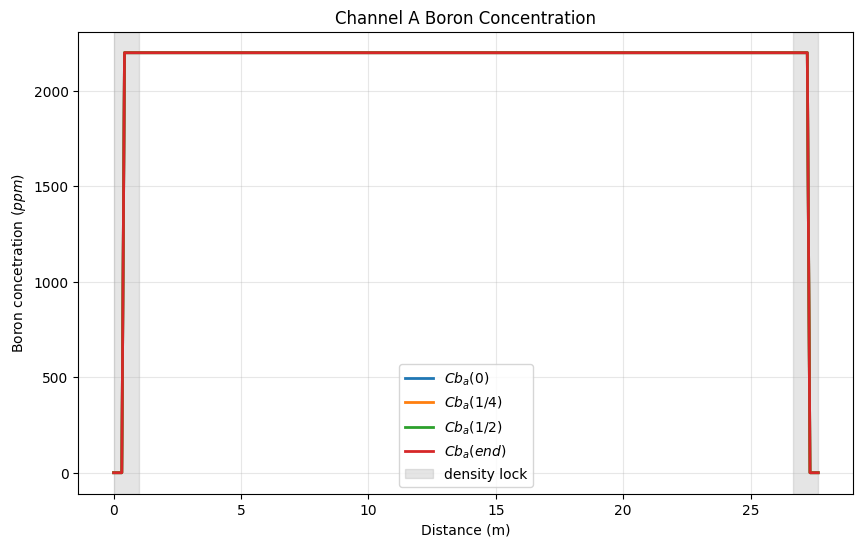

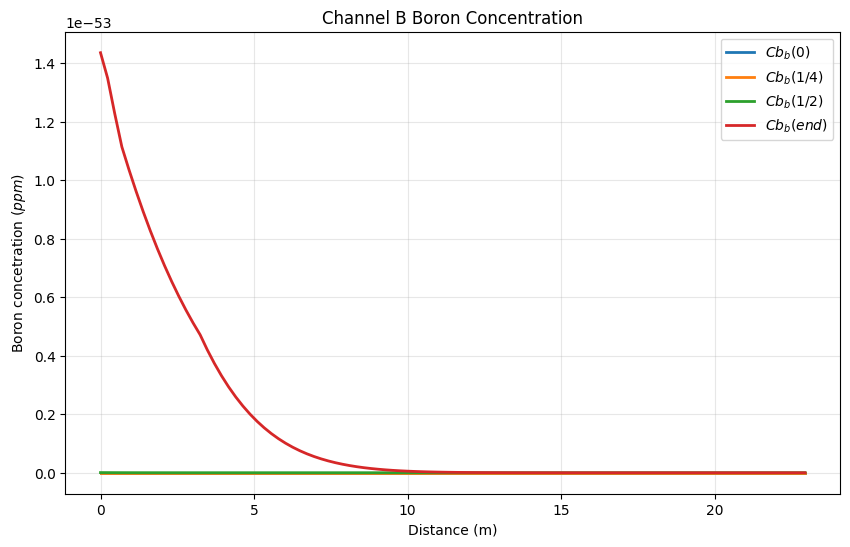

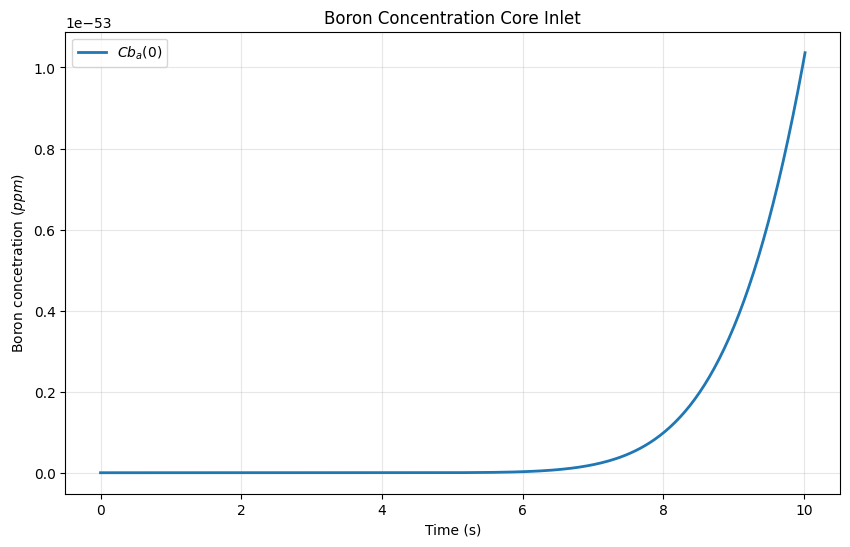

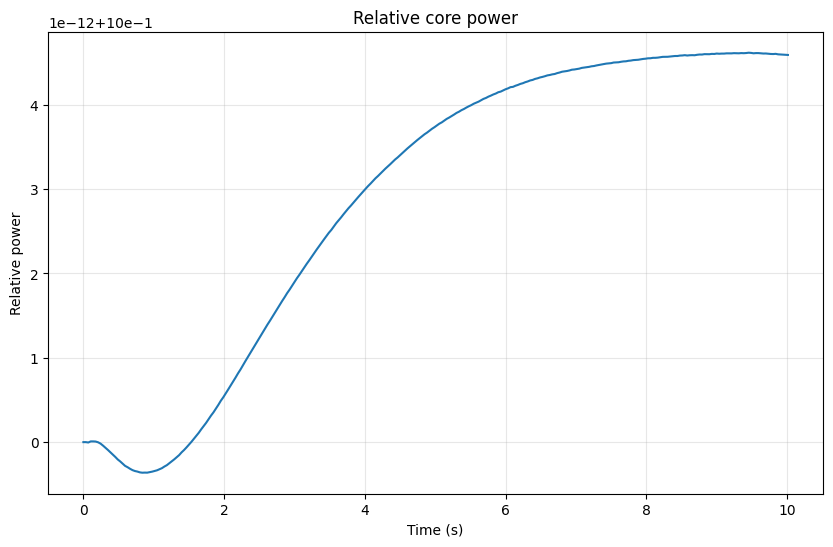

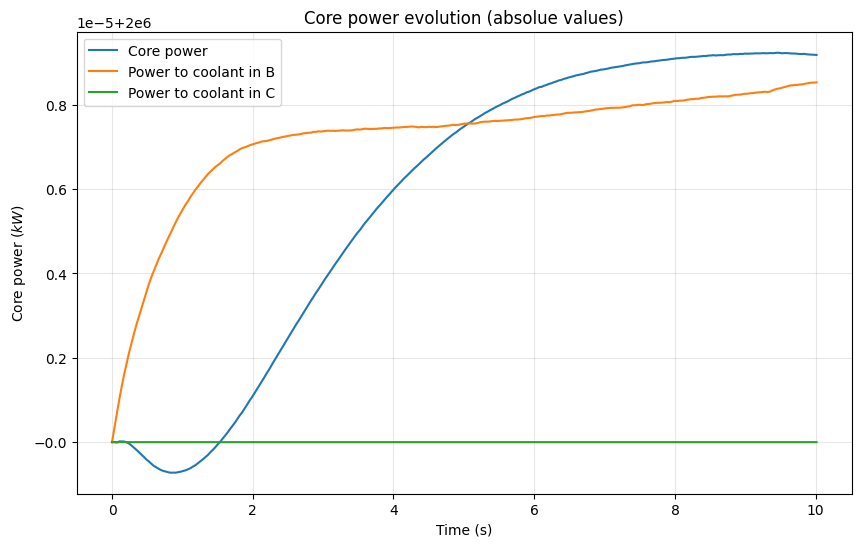

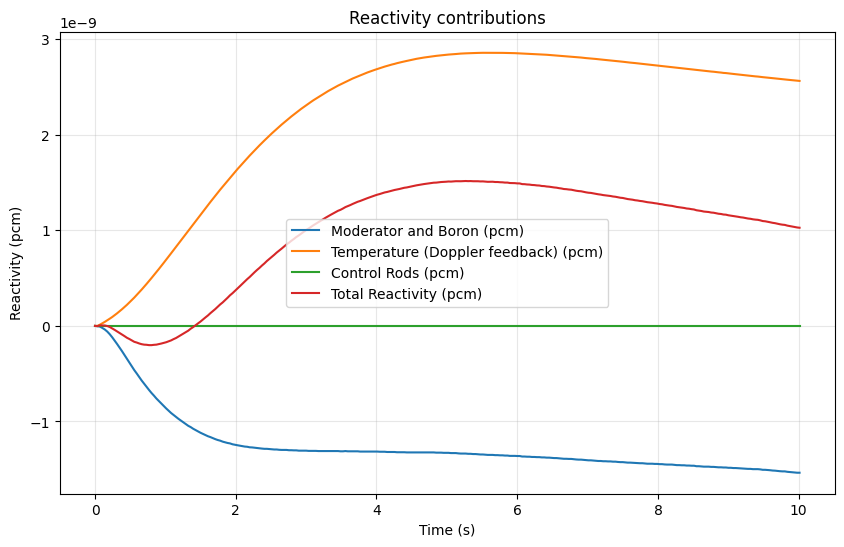

In [2]:
plt.figure(figsize=(10, 6))
plt.plot(t, history['ma'], label='$m_a(t)$', linewidth=2)
#plt.plot(t, history['mb'], label='$m_b(t)$', linewidth=2)
#plt.plot(t, history['mc'], label='$m_c(t)$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Flow Rate ($ kg/s$)')
plt.title('O-PIUS with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, (history['Ja'] + history['Jb']) * g, label='$J_a + J_b $', linewidth=2)
plt.plot(t, (history['Jb'] + history['Jc']) * g, label='$J_b + J_c $', linewidth=2)
plt.plot(t, (history['Ja'] - history['Jc']) * g, label='$J_a - J_c $', linewidth=2)
#plt.plot(t, np.full(len(t), g* h_pump(t) * HB_conc.rho(HB_conc.T_h(i_c_t[:, n_pump]))), label=r'$h_{pump} \rho $', linewidth=1, linestyle = '--')
plt.xlabel('Time (s)')
plt.ylabel('$Pa$')
plt.title('Static head differences with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, history['Ja'] * g, label='$J_a$', linewidth=2)
i_c_pump = history['i_c'][:, n_pump]
plt.plot(t, pump_head(history['t'], h_pump_SS, pump_trip_transient, feedwater_loss_transient) * HB_conc.rho(HB_conc.T_h(i_c_pump)) + history['Jc'] * g, label=r'$h_{pump} \rho _0 + J_c$', linewidth=2)
plt.plot(t, -history['Jb'] * g , label='$-J_b$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Static heads ($Pa$)')
plt.title('Static head with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(x_a, history['i_a'][0, :] , label='$i_a(0)$', linewidth=2)
plt.plot(x_a, history['i_a'][int(len(t)/4), :] , label='$i_a(1/4)$', linewidth=2)
plt.plot(x_a, history['i_a'][int(len(t)/2), :] , label='$i_a(1/2)$', linewidth=2)
plt.plot(x_a, history['i_a'][-1, :] , label='$i_a(1/1)$', linewidth=2)
plt.axvspan(0, L_Udl, color='gray', alpha=0.2, label='density lock')
plt.axvspan(L_a - L_Ldl, L_a, color='gray', alpha=0.2)
plt.xlabel('Distance (m)')
plt.ylabel('Enthalpy ($kJ/kg$)')
plt.title('Channel A with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_b, history['i_b'][0, :] , label='$i_b(0)$', linewidth=2)
plt.plot(x_b, history['i_b'][int(len(t)/4), :] , label='$i_b(1/4)$', linewidth=2)
plt.plot(x_b, history['i_b'][int(len(t)/2), :] , label='$i_b(1/2)$', linewidth=2)
plt.plot(x_b, history['i_b'][-1, :] , label='$i_b(end)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Enthalpy ($kJ/kg$)')
plt.title('Channel B with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_b, history['T_b'][0, :] , label='$T_b(0)$', linewidth=2)
plt.plot(x_b, history['T_b'][int(len(t)/4), :] , label='$T_b(1/4)$', linewidth=2)
plt.plot(x_b, history['T_b'][int(len(t)/2), :] , label='$T_b(1/2)$', linewidth=2)
plt.plot(x_b, history['T_b'][-1, :] , label='$T_b(end)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Temperature (C°)')
plt.title('Channel B with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_c, history['i_c'][0, :] , label='$i_c(0)$', linewidth=2)
plt.plot(x_c, history['i_c'][int(len(t)/4), :] , label='$i_c(1/4)$', linewidth=2)
plt.plot(x_c, history['i_c'][int(len(t)/2), :] , label='$i_c(1/2)$', linewidth=2)
plt.plot(x_c, history['i_c'][-1, :] , label='$i_c(1/1)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Enthalpy ($kJ/kg$)')
plt.title('Channel C with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, history['T_b'][:, idx_exit_core] , label='$T_b$', linewidth=2)
if evaluate_hot: plt.plot(t, history['T_b_hot'][:, idx_exit_core] , label='$T_{b-hot}$', linewidth=2)
plt.plot()
plt.xlabel('Time (s)')
plt.ylabel('Temperature ($C$)')
plt.title('Core outlet temperature in average and hot channel')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, HB_conc.T_h(history['i_c'][:, idx_exit_SG]))
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C°)')
plt.title('Steam generator outlet temperature')
plt.grid(True, alpha=0.3)
plt.show()
    
plt.figure(figsize=(10, 6))
plt.plot(x_a, history['Cb_a'][0, :] , label='$Cb_a(0)$', linewidth=2)
plt.plot(x_a, history['Cb_a'][int(len(t)/4), :] , label='$Cb_a(1/4)$', linewidth=2)
plt.plot(x_a, history['Cb_a'][int(len(t)/2), :] , label='$Cb_a(1/2)$', linewidth=2)
plt.plot(x_a, history['Cb_a'][-1, :] , label='$Cb_a(end)$', linewidth=2)
plt.axvspan(0, L_Udl, color='gray', alpha=0.2, label='density lock')
plt.axvspan(L_a - L_Ldl, L_a, color='gray', alpha=0.2)
plt.xlabel('Distance (m)')
plt.ylabel('Boron concetration ($ppm$)')
plt.title('Channel A Boron Concentration')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_b, history['Cb_b'][0, :] , label='$Cb_b(0)$', linewidth=2)
plt.plot(x_b, history['Cb_b'][int(len(t)/4), :] , label='$Cb_b(1/4)$', linewidth=2)
plt.plot(x_b, history['Cb_b'][int(len(t)/2), :] , label='$Cb_b(1/2)$', linewidth=2)
plt.plot(x_b, history['Cb_b'][-1, :] , label='$Cb_b(end)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Boron concetration ($ppm$)')
plt.title('Channel B Boron Concentration')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, history['Cb_b'][: , idx_start_core], label='$Cb_a(0)$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Boron concetration ($ppm$)')
plt.title('Boron Concentration Core Inlet')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, history['Q_core'] / Q_core_SS)
plt.xlabel('Time (s)')
plt.ylabel('Relative power')
plt.title('Relative core power')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, np.abs(history['Q_core']), label='Core power')
plt.plot(t, np.abs(history['P_b']), label='Power to coolant in B')
plt.plot(t, np.abs(history['P_c']), label='Power to coolant in C')
plt.xlabel('Time (s)')
plt.ylabel('Core power ($kW$)')
plt.title('Core power evolution (absolue values)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# reactivity evolution
if nonlinear_PK:
    total_moderator_boron_reactivity = p(history['T_avg_core'], history['Cb_avg'] + SS_boron_concentration, MB_3rd_degree_polynomial_interpolation_coeffs) + MB_normalization_constant
    total_doppler_reactivity = (history['T_avg_fuel'] - history['T_avg_fuel'][0] ) * alpha_doppler
    total_CR_reactivity = rho_CR_func(t)
    total_reactivity = total_moderator_boron_reactivity + total_doppler_reactivity + total_CR_reactivity
    plt.figure(figsize=(10, 6))
    plt.plot(t, total_moderator_boron_reactivity, label=f'Moderator and Boron (pcm)')
    plt.plot(t, total_doppler_reactivity, label=f'Temperature (Doppler feedback) (pcm)')
    plt.plot(t, total_CR_reactivity, label=f'Control Rods (pcm)')
    plt.plot(t, total_reactivity, label=f'Total Reactivity (pcm)')
    plt.xlabel('Time (s)')
    plt.ylabel('Reactivity (pcm)')
    plt.title('Reactivity contributions')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    total_boron_reactivity = (history['Cb_avg'] - history['Cb_avg'][0]) * alpha_B  # in pcm, in the point kinetics function it's not in pcm
    total_moderator_reactivity = (history['T_avg_core'] - history['T_avg_core'][0]) * alpha_M
    total_doppler_reactivity = (history['T_avg_fuel'] - history['T_avg_fuel'][0]) * alpha_doppler
    total_CR_reactivity = rho_CR_func(t)
    total_reactivity = total_boron_reactivity + total_moderator_reactivity + total_doppler_reactivity + total_CR_reactivity
    plt.figure(figsize=(10, 6))
    plt.plot(t, total_boron_reactivity, label=f'Boron (pcm)')
    plt.plot(t, total_moderator_reactivity, label=f'Temperature (Moderator) (pcm)')
    plt.plot(t, total_doppler_reactivity, label=f'Temperature (Doppler feedback) (pcm)')
    plt.plot(t, total_CR_reactivity, label=f'Control Rods (pcm)')
    plt.plot(t, total_reactivity, label=f'Total Reactivity (pcm)')
    plt.xlabel('Time (s)')
    plt.ylabel('Reactivity (pcm)')
    plt.title('Reactivity contributions')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


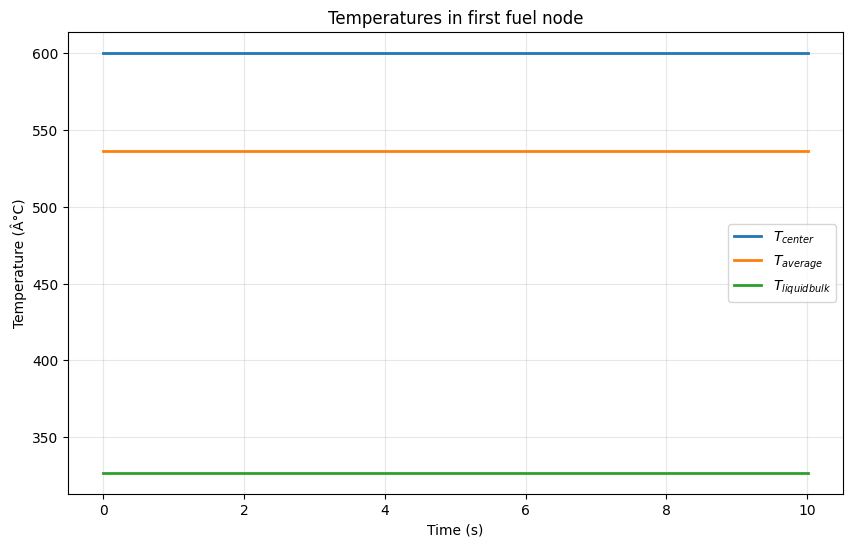

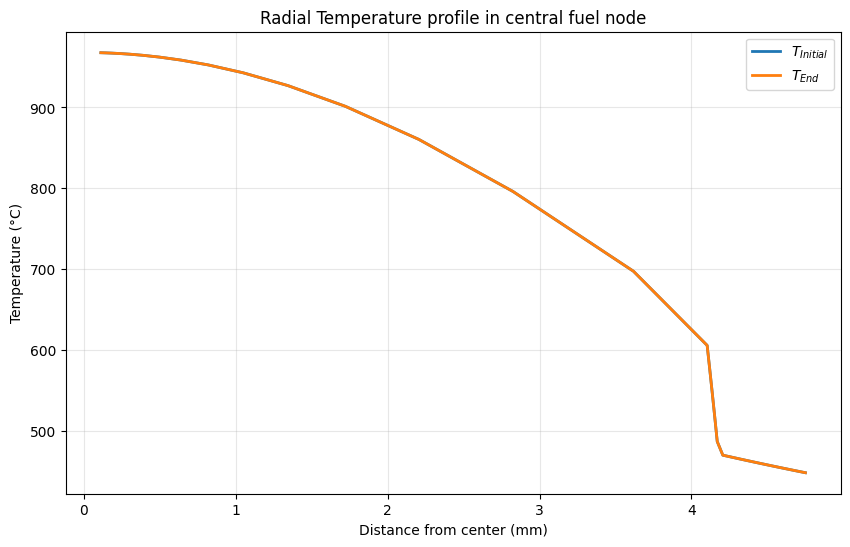

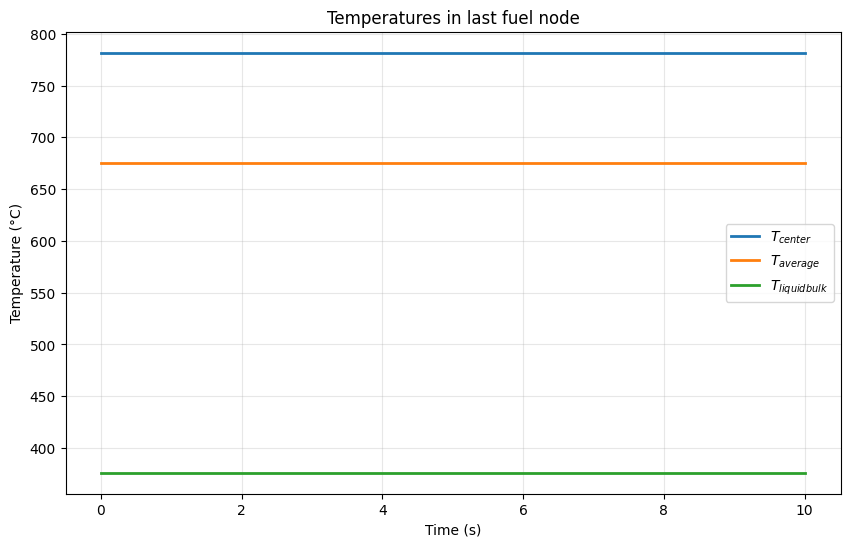

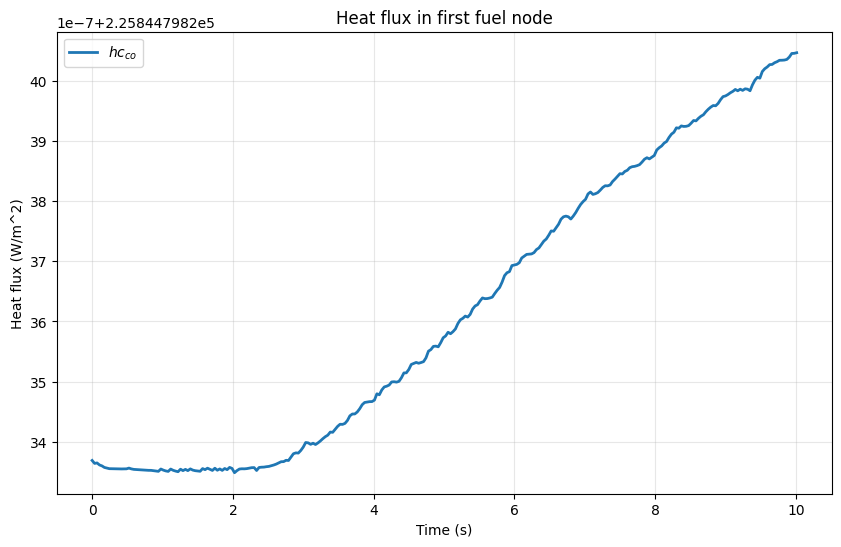

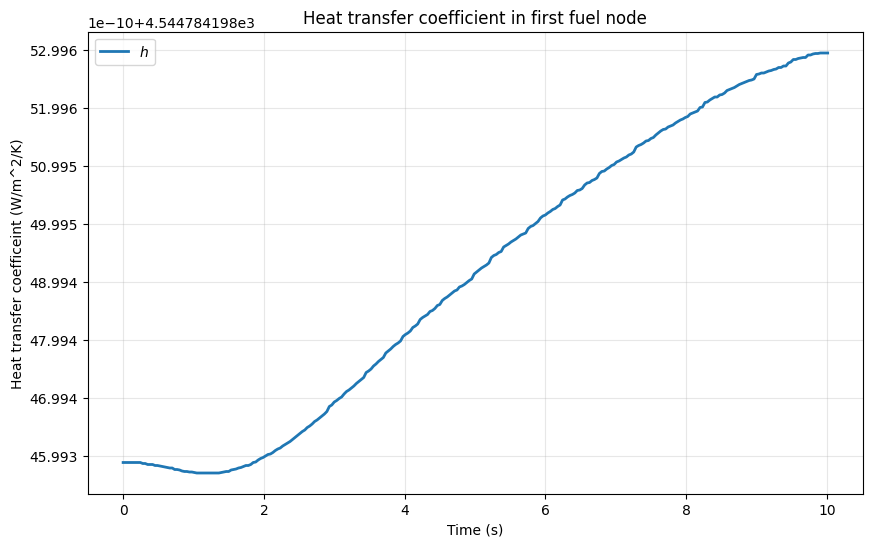

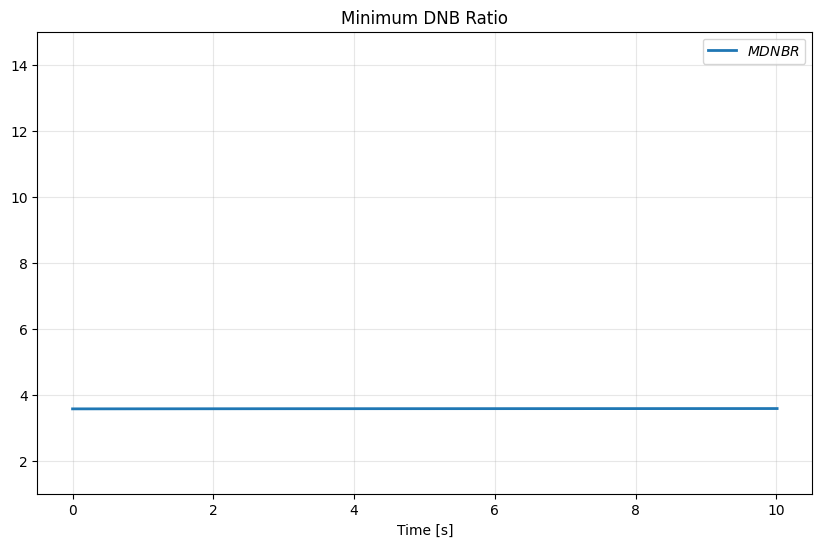

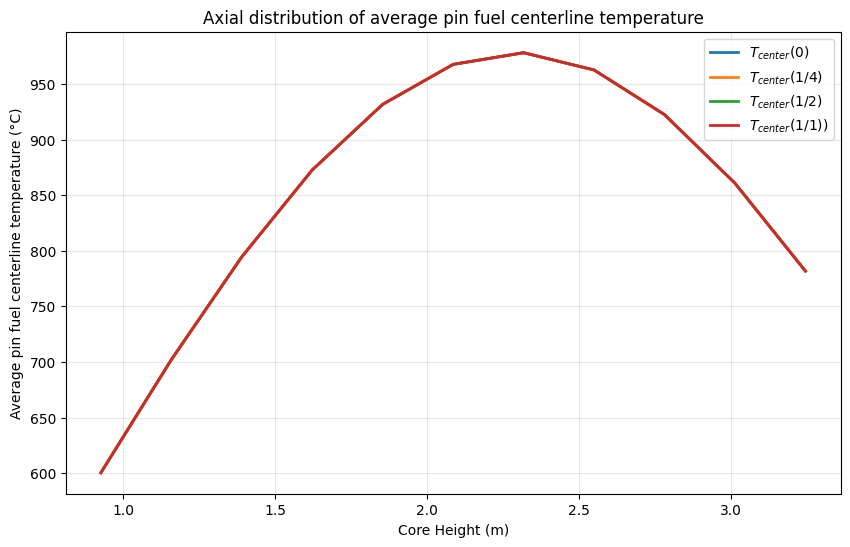

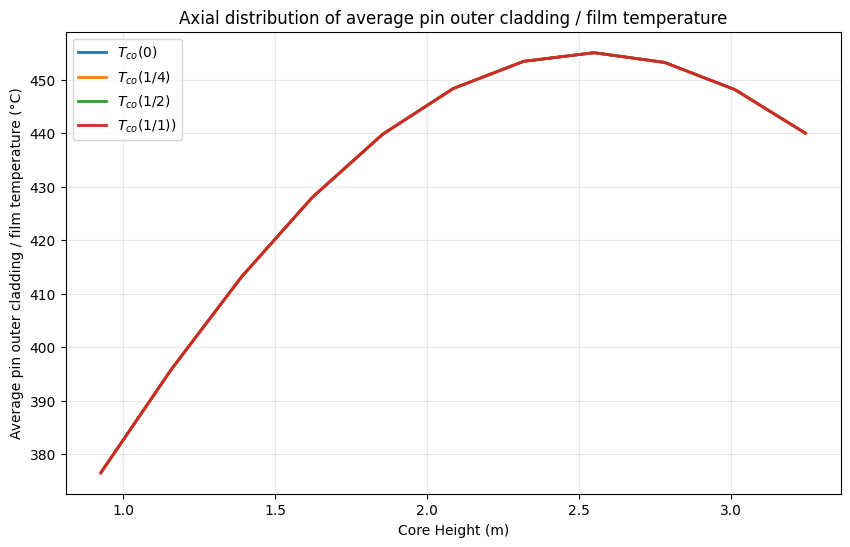

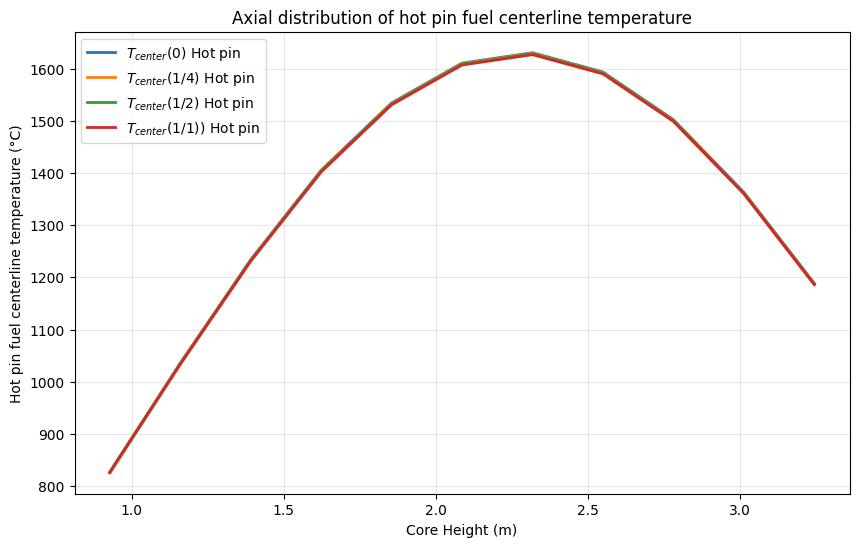

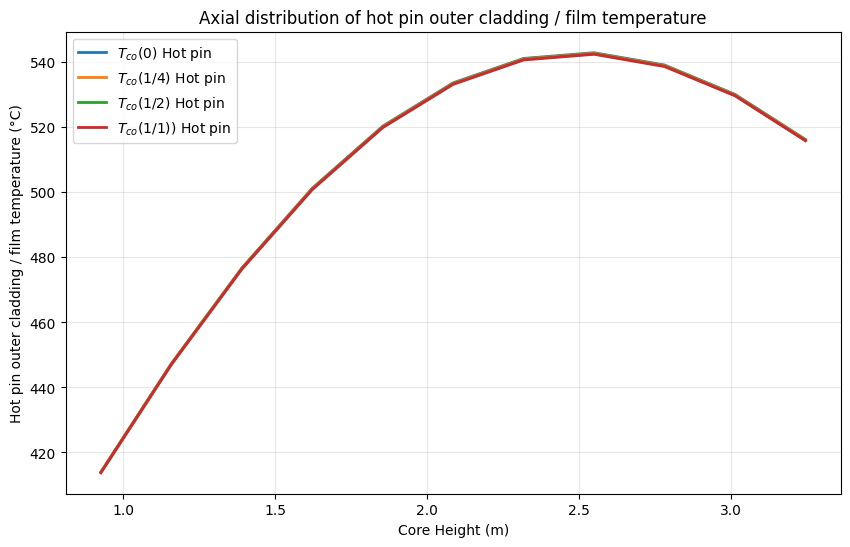

In [6]:
fuel_nodes = []
hot_fuel_nodes = []
first_fuel_node = None
last_fuel_node = None
for i in range(len(core)):
    if core[i] is not None:
        fuel_nodes.append(core[i])
        if evaluate_hot : hot_fuel_nodes.append(core_hot[i])
        if first_fuel_node is None:
            first_fuel_node = core[i]
        last_fuel_node = core[i]
'''
# Evolution of first node temperatures
plt.figure(figsize=(10, 6))
plt.plot(first_fuel_node.t, first_fuel_node.T_centerline , label=r'$T_{center}$', linewidth=2)
plt.plot(first_fuel_node.t, first_fuel_node.average_fuel_T , label=r'$T_{average}$', linewidth=2)
plt.plot(first_fuel_node.t, first_fuel_node.T_lb, label=r'$T_{liquid bulk}$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Temperature (°C)')
plt.title('Temperatures in first fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


central_fuel_node = fuel_nodes[int(np.floor(len(fuel_nodes)/ 2))]
plt.figure(figsize=(10, 6))
plt.plot(central_fuel_node.r * 1000, central_fuel_node.T[0, :], label=r'$T_{Initial}$', linewidth=2)
plt.plot(central_fuel_node.r * 1000, central_fuel_node.T[len(t)-1, :], label=r'$T_{End}$', linewidth=2)
plt.xlabel('Distance from center (mm)')
plt.ylabel('Temperature (°C)')
plt.title('Radial Temperature profile in central fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(last_fuel_node.t, last_fuel_node.T_centerline , label=r'$T_{center}$', linewidth=2)
plt.plot(last_fuel_node.t, last_fuel_node.average_fuel_T , label=r'$T_{average}$', linewidth=2)
plt.plot(last_fuel_node.t, last_fuel_node.T_lb, label=r'$T_{liquid bulk}$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Temperature (°C)')
plt.title('Temperatures in last fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(first_fuel_node.t, first_fuel_node.hf_co , label=r'$hc_{co}$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Heat flux (W/m^2)')
plt.title('Heat flux in first fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(first_fuel_node.t, first_fuel_node.h , label=r'$h$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Heat transfer coefficeint (W/m^2/K)')
plt.title('Heat transfer coefficient in first fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
'''
if evaluate_CHF:
    plt.figure(figsize=(10, 6))
    plt.plot(t, history['MDNBR'] , label='$MDNBR$', linewidth=2)
    plt.xlabel('Time [s]')
    plt.ylim(bottom=1,top=15)
    plt.title('Minimum DNB Ratio')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Axial distribution of average pin centerline temperature
zs = [node.z for node in fuel_nodes]
center_T_init = [node.T_centerline[0] for node in fuel_nodes]
center_T_quarter = [node.T_centerline[int(len(t)/4)] for node in fuel_nodes]
center_T_middle = [node.T_centerline[int(len(t)/2)] for node in fuel_nodes]
center_T_end = [node.T_centerline[-1] for node in fuel_nodes]
plt.figure(figsize=(10, 6))
plt.plot(zs, center_T_init , label=r'$T_{center}(0)$', linewidth=2)
plt.plot(zs, center_T_quarter, label=r'$T_{center}(1/4)$', linewidth=2)
plt.plot(zs, center_T_middle, label=r'$T_{center}(1/2)$', linewidth=2)
plt.plot(zs, center_T_end, label=r'$T_{center}(1/1))$', linewidth=2)
plt.xlabel('Core Height (m)')
plt.ylabel('Average pin fuel centerline temperature (°C)')
plt.title('Axial distribution of average pin fuel centerline temperature')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Axial distribution of average pin outer cladding / film temperature
zs = [node.z for node in fuel_nodes]
co_T_init = [node.T[0][node.N] for node in fuel_nodes]
co_T_quarter = [node.T[int(len(t)/4)][node.N] for node in fuel_nodes]
co_T_middle = [node.T[int(len(t)/2)][node.N] for node in fuel_nodes]
co_T_end = [node.T[-1][node.N] for node in fuel_nodes]
plt.figure(figsize=(10, 6))
plt.plot(zs, co_T_init , label=r'$T_{co}(0)$', linewidth=2)
plt.plot(zs, co_T_quarter, label=r'$T_{co}(1/4)$', linewidth=2)
plt.plot(zs, co_T_middle, label=r'$T_{co}(1/2)$', linewidth=2)
plt.plot(zs, co_T_end, label=r'$T_{co}(1/1))$', linewidth=2)
plt.xlabel('Core Height (m)')
plt.ylabel('Average pin outer cladding / film temperature (°C)')
plt.title('Axial distribution of average pin outer cladding / film temperature')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


if evaluate_hot :
    # Axial distribution of hot pin centerline temperature
    zs = [node.z for node in hot_fuel_nodes]
    center_T_init = [node.T_centerline[0] for node in hot_fuel_nodes]
    center_T_quarter = [node.T_centerline[int(len(t)/4)] for node in hot_fuel_nodes]
    center_T_middle = [node.T_centerline[int(len(t)/2)] for node in hot_fuel_nodes]
    center_T_end = [node.T_centerline[-1] for node in hot_fuel_nodes]
    plt.figure(figsize=(10, 6))
    plt.plot(zs, center_T_init , label=r'$T_{center}(0)$ Hot pin', linewidth=2)
    plt.plot(zs, center_T_quarter, label=r'$T_{center}(1/4)$ Hot pin', linewidth=2)
    plt.plot(zs, center_T_middle, label=r'$T_{center}(1/2)$ Hot pin', linewidth=2)
    plt.plot(zs, center_T_end, label=r'$T_{center}(1/1))$ Hot pin', linewidth=2)
    plt.xlabel('Core Height (m)')
    plt.ylabel('Hot pin fuel centerline temperature (°C)')
    plt.title('Axial distribution of hot pin fuel centerline temperature')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    # Axial distribution of hot pin outer cladding / film temperature
    zs = [node.z for node in hot_fuel_nodes]
    co_T_init = [node.T[0][node.N] for node in hot_fuel_nodes]
    co_T_quarter = [node.T[int(len(t)/4)][node.N] for node in hot_fuel_nodes]
    co_T_middle = [node.T[int(len(t)/2)][node.N] for node in hot_fuel_nodes]
    co_T_end = [node.T[-1][node.N] for node in hot_fuel_nodes]
    plt.figure(figsize=(10, 6))
    plt.plot(zs, co_T_init , label=r'$T_{co}(0)$ Hot pin', linewidth=2)
    plt.plot(zs, co_T_quarter, label=r'$T_{co}(1/4)$ Hot pin', linewidth=2)
    plt.plot(zs, co_T_middle, label=r'$T_{co}(1/2)$ Hot pin', linewidth=2)
    plt.plot(zs, co_T_end, label=r'$T_{co}(1/1))$ Hot pin', linewidth=2)
    plt.xlabel('Core Height (m)')
    plt.ylabel('Hot pin outer cladding / film temperature (°C)')
    plt.title('Axial distribution of hot pin outer cladding / film temperature')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()